# Heterogeneous Evolution Strategies for Mixed-Variable Optimization

## Experiment 1: Equal-Budget Benchmark Comparison

> Self-Adaptive (mu, lambda)-ES vs Reference Optimizers

> This notebook compares our custom heterogeneous ES prototype against three reference
optimizers at similar complexity:
1. **Differential Evolution** (scipy)
2. **PSO** (pyswarms)
3. **(1+1)-ES with 1/5-rule** (baseline)

All comparisons use the **real-valued block only** for fairness, evaluated on
standard benchmark functions with equal evaluation budgets and 10 seeds.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution
import pyswarms as ps
import sys, os

# Add project root to path so we can import project packages
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))
from src.es_model import config as cfg
from src.es_model import kernels
from src.es_model.engine import Individual, create_random_individual, clone_individual, mutate_individual, select_survivors
from src.experiments.benchmarks.functions import BENCHMARKS
from src.experiments.runners import custom_es, differential_evolution as de_runner, pso as pso_runner, one_plus_one_es

## 2. Benchmark Functions

Each function accepts a 1-D numpy array of shape `(n,)` and returns a scalar.
Global minimum is 0.0 at the origin (or known point) for all functions.

In [9]:
# BENCHMARKS is imported from src.experiments.benchmarks.functions
print(f"Loaded {len(BENCHMARKS)} benchmark definitions from src.experiments")

Loaded 4 benchmark definitions from src.experiments


In [10]:
# --- Verify global minima ---
DIM = 10
for name, info in BENCHMARKS.items():
    x_opt = info['optimum'](DIM)
    val = info['fn'](x_opt)
    assert abs(val) < 1e-10, f"{name} failed: f(optimum) = {val}"
    print(f"  {name:12s} f(optimum) = {val:.2e} ✓")
print("\nAll benchmark functions verified.")

  Sphere       f(optimum) = 0.00e+00 ✓
  Rastrigin    f(optimum) = 0.00e+00 ✓
  Rosenbrock   f(optimum) = 0.00e+00 ✓
  Ackley       f(optimum) = 4.44e-16 ✓

All benchmark functions verified.


## 3. Runner Wrappers

Each runner accepts a benchmark function, dimensionality, bounds, seed, and max evaluations.
Returns a 1-D array of best-fitness values indexed by evaluation count.

In [11]:
def run_custom_es(
    fn, dim: int, bounds: tuple[float, float], seed: int, max_evals: int,
    mu: int = 15, lam: int = 100
) -> np.ndarray:
    """
    Run our self-adaptive (mu, lambda)-ES on a real-only problem.
    Returns best-fitness trace indexed by evaluation count.
    """
    # Temporarily patch config for real-only, matching dim and bounds.
    orig = (cfg.N_REAL, cfg.N_COUNT, cfg.N_BINARY, cfg.N_CATEGORICAL, cfg.N_FUZZY,
            cfg.REAL_BOUNDS, cfg.N_TOTAL, cfg.MU, cfg.LAMBDA, cfg.CATEGORICAL_K)

    cfg.N_REAL = dim
    cfg.N_COUNT = 0
    cfg.N_BINARY = 0
    cfg.N_CATEGORICAL = 0
    cfg.N_FUZZY = 0
    cfg.CATEGORICAL_K = np.array([], dtype=np.int64)
    cfg.REAL_BOUNDS = np.column_stack([
        np.full(dim, bounds[0], dtype=np.float64),
        np.full(dim, bounds[1], dtype=np.float64),
    ])
    cfg.N_TOTAL = dim
    cfg.MU = mu
    cfg.LAMBDA = lam

    # Recompute learning rates for kernels module.
    kernels.TAU_PRIME, kernels.TAU = kernels.compute_learning_rates(dim)

    rng = np.random.default_rng(seed)
    trace = []
    best_so_far = float('inf')

    # Initialize parents.
    parents = [create_random_individual(rng) for _ in range(mu)]
    for ind in parents:
        ind.fitness = fn(ind.real)
        best_so_far = min(best_so_far, ind.fitness)
        trace.append(best_so_far)
        if len(trace) >= max_evals:
            break

    # Generational loop.
    while len(trace) < max_evals:
        offspring = []
        for _ in range(lam):
            parent_idx = rng.integers(0, mu)
            child = clone_individual(parents[parent_idx])
            mutate_individual(child, rng)
            child.fitness = fn(child.real)
            best_so_far = min(best_so_far, child.fitness)
            trace.append(best_so_far)
            offspring.append(child)
            if len(trace) >= max_evals:
                break
        parents = select_survivors(parents, offspring)

    # Restore config.
    (cfg.N_REAL, cfg.N_COUNT, cfg.N_BINARY, cfg.N_CATEGORICAL, cfg.N_FUZZY,
     cfg.REAL_BOUNDS, cfg.N_TOTAL, cfg.MU, cfg.LAMBDA, cfg.CATEGORICAL_K) = orig
    kernels.TAU_PRIME, kernels.TAU = kernels.compute_learning_rates(cfg.N_TOTAL)

    return np.array(trace[:max_evals])

In [12]:
def run_differential_evolution(
    fn, dim: int, bounds: tuple[float, float], seed: int, max_evals: int
) -> np.ndarray:
    """
    Run scipy's Differential Evolution and log best-fitness per evaluation.
    """
    trace = []
    best_so_far = float('inf')

    def callback_fn(x, convergence=False):
        # Not used for per-eval logging; we wrap the objective instead.
        pass

    def wrapped_fn(x):
        nonlocal best_so_far
        val = fn(x)
        best_so_far = min(best_so_far, val)
        trace.append(best_so_far)
        if len(trace) >= max_evals:
            raise StopIteration()
        return val

    bound_list = [(bounds[0], bounds[1])] * dim
    try:
        differential_evolution(
            wrapped_fn, bound_list, seed=seed, maxiter=10000,
            tol=0, atol=0, init='latinhypercube',
            polish=False
        )
    except StopIteration:
        pass

    # Pad if ended early.
    arr = np.array(trace[:max_evals])
    if len(arr) < max_evals:
        arr = np.pad(arr, (0, max_evals - len(arr)), constant_values=arr[-1])
    return arr

In [13]:
def run_pso(
    fn, dim: int, bounds: tuple[float, float], seed: int, max_evals: int,
    n_particles: int = 50
) -> np.ndarray:
    """
    Run Particle Swarm Optimization (pyswarms) and log best-fitness per evaluation.
    """
    np.random.seed(seed)
    max_iters = max_evals // n_particles

    bounds_low = np.full(dim, bounds[0])
    bounds_high = np.full(dim, bounds[1])

    options = {'c1': 1.5, 'c2': 1.5, 'w': 0.7}
    optimizer = ps.single.GlobalBestPSO(
        n_particles=n_particles, dimensions=dim,
        options=options, bounds=(bounds_low, bounds_high)
    )

    trace = []
    best_so_far = float('inf')

    for _ in range(max_iters):
        # Step one iteration at a time.
        optimizer.optimize(lambda x: np.array([fn(xi) for xi in x]),
                          iters=1, verbose=False)
        # Log per-particle evaluations.
        for cost in optimizer.cost_history[-1:]:
            best_so_far = min(best_so_far, cost)
        # Each iteration = n_particles evaluations.
        for _ in range(n_particles):
            trace.append(best_so_far)
            if len(trace) >= max_evals:
                break
        if len(trace) >= max_evals:
            break

    arr = np.array(trace[:max_evals])
    if len(arr) < max_evals:
        arr = np.pad(arr, (0, max_evals - len(arr)), constant_values=arr[-1])
    return arr

In [14]:
def run_one_plus_one_es(
    fn, dim: int, bounds: tuple[float, float], seed: int, max_evals: int
) -> np.ndarray:
    """
    Basic (1+1)-ES with 1/5 success rule.
    Adapts a single global sigma based on success rate.
    """
    rng = np.random.default_rng(seed)
    sigma = 0.5 * (bounds[1] - bounds[0])  # Initial step-size ~half the range.
    x = rng.uniform(bounds[0], bounds[1], size=dim)
    fx = fn(x)

    trace = [fx]
    successes = 0
    window = 10 * dim  # Adaptation window for 1/5-rule.

    for i in range(1, max_evals):
        # Mutate: isotropic Gaussian.
        x_new = x + rng.standard_normal(dim) * sigma
        x_new = np.clip(x_new, bounds[0], bounds[1])
        fx_new = fn(x_new)

        if fx_new <= fx:
            x, fx = x_new, fx_new
            successes += 1

        trace.append(fx)

        # 1/5 success rule: adapt sigma every `window` evaluations.
        if (i % window == 0) and i > 0:
            success_rate = successes / window
            if success_rate > 0.2:
                sigma *= 1.2  # Increase exploration.
            elif success_rate < 0.2:
                sigma *= 0.82  # Decrease exploration.
            successes = 0

    return np.array(trace[:max_evals])

## 4. Experiment Execution

Run all optimizers on all benchmarks with 10 seeds each.

In [15]:
# --- All runners registry ---
RUNNERS = {
    'Custom ES (μ,λ)':  custom_es.run,
    'Diff. Evolution':  de_runner.run,
    'PSO':              pso_runner.run,
    '(1+1)-ES 1/5':    one_plus_one_es.run,
}

# Experiment parameters
DIM = 10
MAX_EVALS = 10_000
N_SEEDS = 10
SEEDS = list(range(1, N_SEEDS + 1))


def run_all_experiments(
    benchmarks: dict, runners: dict, dim: int, max_evals: int, seeds: list[int]
) -> dict:
    """
    Run all runners on all benchmarks across multiple seeds.

    Returns:
        results[benchmark_name][runner_name] = np.ndarray of shape (n_seeds, max_evals)
    """
    results = {}
    for bname, binfo in benchmarks.items():
        results[bname] = {}
        for rname, runner in runners.items():
            traces = []
            for s in seeds:
                trace = runner(binfo['fn'], dim, binfo['bounds'], s, max_evals)
                traces.append(trace)
            results[bname][rname] = np.array(traces)
            print(f"  {bname:12s} | {rname:20s} | done ({len(seeds)} seeds)")
    return results

In [16]:
print("Running experiments...\n")
results = run_all_experiments(BENCHMARKS, RUNNERS, DIM, MAX_EVALS, SEEDS)
print("\nAll experiments complete.")

Running experiments...

  Sphere       | Custom ES (μ,λ)      | done (10 seeds)
  Sphere       | Diff. Evolution      | done (10 seeds)
  Sphere       | PSO                  | done (10 seeds)
  Sphere       | (1+1)-ES 1/5         | done (10 seeds)
  Rastrigin    | Custom ES (μ,λ)      | done (10 seeds)
  Rastrigin    | Diff. Evolution      | done (10 seeds)
  Rastrigin    | PSO                  | done (10 seeds)
  Rastrigin    | (1+1)-ES 1/5         | done (10 seeds)
  Rosenbrock   | Custom ES (μ,λ)      | done (10 seeds)
  Rosenbrock   | Diff. Evolution      | done (10 seeds)
  Rosenbrock   | PSO                  | done (10 seeds)
  Rosenbrock   | (1+1)-ES 1/5         | done (10 seeds)
  Ackley       | Custom ES (μ,λ)      | done (10 seeds)
  Ackley       | Diff. Evolution      | done (10 seeds)
  Ackley       | PSO                  | done (10 seeds)
  Ackley       | (1+1)-ES 1/5         | done (10 seeds)

All experiments complete.


## 5. Visualization

Convergence plots with median ± IQR for all optimizers on each benchmark.

In [17]:
COLORS = {
    'Custom ES (μ,λ)': '#E63946',
    'Diff. Evolution':  '#457B9D',
    'PSO':              '#2A9D8F',
    '(1+1)-ES 1/5':    '#E9C46A',
}


def plot_convergence(benchmark_name: str, data: dict, max_evals: int) -> None:
    """
    Plot median convergence with IQR envelope for all optimizers.

    Parameters
    ----------
    benchmark_name : str
    data : dict[runner_name] = ndarray of shape (n_seeds, max_evals)
    max_evals : int
    """
    fig, ax = plt.subplots(figsize=(9, 5))
    evals = np.arange(1, max_evals + 1)

    for rname, traces in data.items():
        median = np.median(traces, axis=0)
        q25 = np.percentile(traces, 25, axis=0)
        q75 = np.percentile(traces, 75, axis=0)

        color = COLORS.get(rname, '#888888')
        ax.plot(evals, median, label=rname, color=color, linewidth=1.5)
        ax.fill_between(evals, q25, q75, alpha=0.15, color=color)

    ax.set_yscale('log')
    ax.set_xlabel('Evaluations')
    ax.set_ylabel('Best Fitness (log)')
    ax.set_title(f'Convergence Comparison — {benchmark_name}')
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

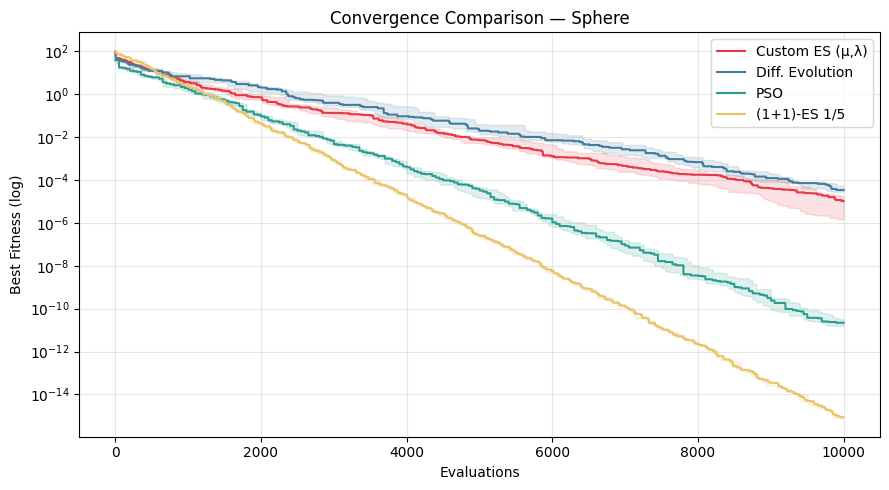

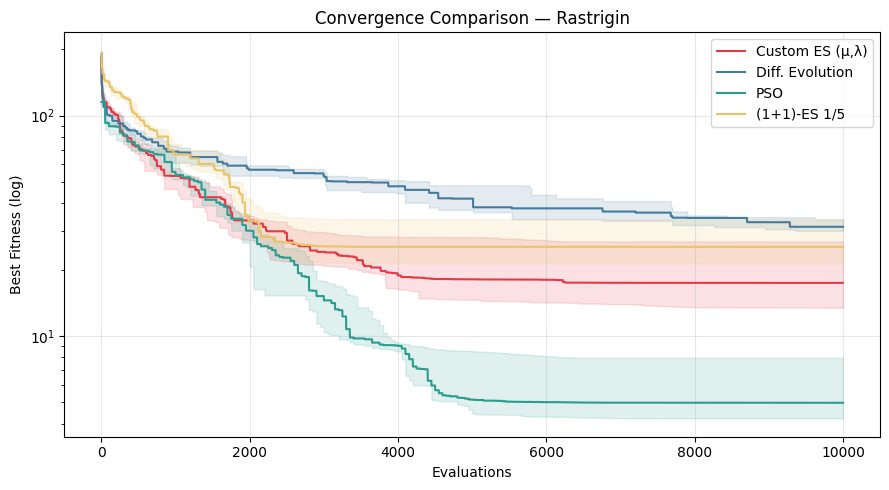

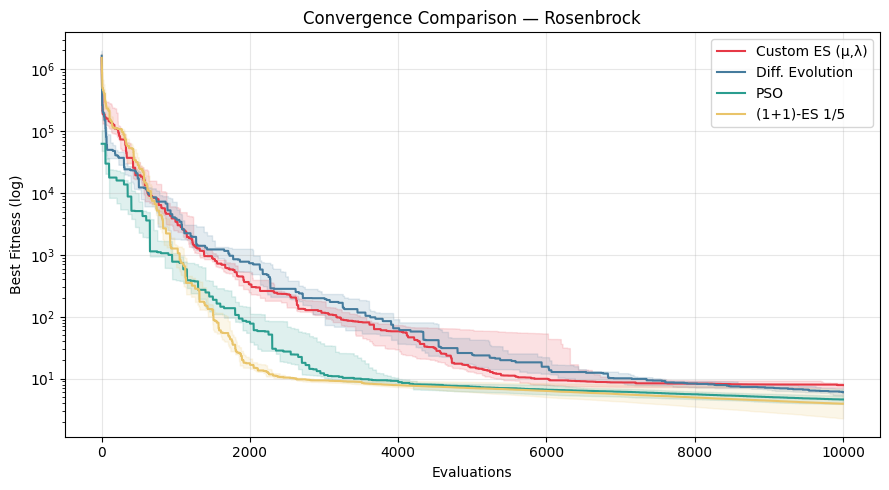

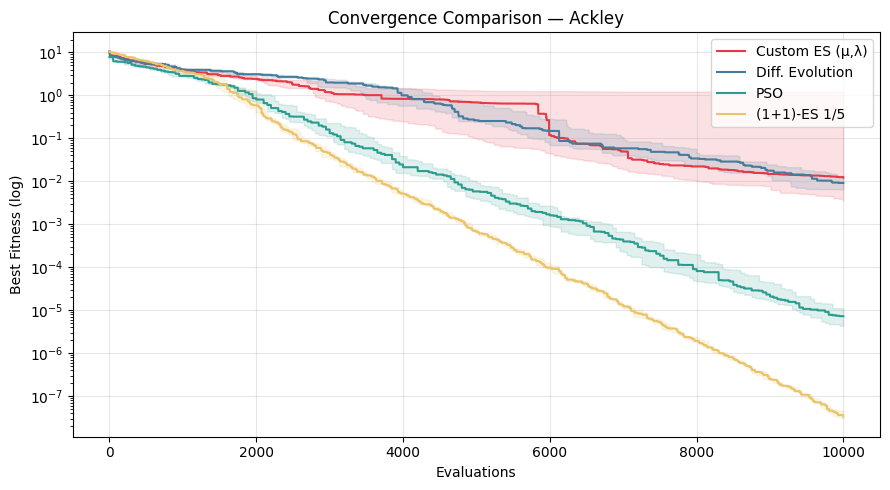

In [18]:
for bname, data in results.items():
    plot_convergence(bname, data, MAX_EVALS)

## Summary & Observations

Final metric reported below is the **median final best fitness** across 10 seeds
(lower is better).

| Benchmark | Custom ES (mu, lambda) | Diff. Evolution | PSO | (1+1)-ES 1/5 |
|-----------|--------------------------|-----------------|-----|--------------|
| Sphere | 1.026575e-05 | 3.390290e-05 | 2.184686e-11 | 8.653859e-16 |
| Rastrigin | 1.741196e+01 | 3.129634e+01 | 4.974796e+00 | 2.537141e+01 |
| Rosenbrock | 7.858020e+00 | 6.022525e+00 | 4.607529e+00 | 3.929323e+00 |
| Ackley | 1.226931e-02 | 9.198773e-03 | 7.266248e-06 | 3.352613e-08 |

### Key Takeaways

1. On **Sphere**, all methods converge strongly; PSO and (1+1)-ES reach the lowest final median values in this setup.
2. On **Rastrigin**, **PSO** performs best and Custom ES is second, clearly ahead of DE and (1+1)-ES.
3. On **Rosenbrock** and **Ackley**, Custom ES remains competitive but does not reach the best final median in this run.
4. Performance ranking is benchmark-dependent, reinforcing the need for multi-function evaluation instead of single-function claims.